We will start by importing the necessary libraries for exploring the data

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Load data and separate target to rest of dataset
raw = pd.read_csv('Telco-Customer-Churn.csv')
churn = raw['Churn']
data = raw.drop(['Churn', 'customerID'],axis=1)

# Success
print('Data loaded successfully.')

Data loaded successfully.


## Exploratory Data Analysis

### Exploring the dataset

In [18]:
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


---

In [32]:
missing = data.isna().sum()
missing_cols = missing[missing > 0].sort_values(ascending=False)
if len(missing_cols)>0:
    print(missing_cols)
else:
    print('No columns with missing values')

No columns with missing values


In [42]:
print(churn.value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


We notice that there is a moderate class imbalance in the data. This is significant as it allows us to consider evaluation metrics in a more stringent manner. A model that predicts 'No' only would achieve around 73/74% accuracy despite identifying no actual churners. We must consider our recall, precision, f1-score, and ROC-AUC metrics as more important metrics of evaluation.

- Recall: how many positives did the model predict against all the positives that exist -> higher means we got more real positive cases, but also can predict more false positives (avoids false negatives)
- Precision: a little more strict - models how many actual positives against all the predictions -> higher means we got more reliable predictions, lowering false positives but also can predict more false negatives (avoids false alarms)

---

For clarity, we will store the numerical and categorical columns in separate variables.

In [3]:
num_cols = data.select_dtypes(include=np.number).columns
cat_cols = data.select_dtypes(include='str').columns

print(num_cols)
print(cat_cols)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges'], dtype='str')
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'TotalCharges'],
      dtype='str')


### Exploratory Feature Analysis: Contract vs. Churn

We will start by performing univariate feature analysis with Contract and its relationship to churn. We will start by creating a contingency table between the two. Using normalize, we will create a relative frequency table. By changing the parameter `normalize`, between index and column, we will get, respectively, the distribution of:
1. Whether customer churned given their contract type
2. Customers' contract type given whether they churned

In [64]:
# Display relative frequency tables for conditional probabilities
print("Churn among contract types:\n{}".format(pd.crosstab(data['Contract'],churn,normalize='index').round(3)))
print("\nContract types among churn:\n{}".format(pd.crosstab(data['Contract'],churn,normalize='columns').round(3)))


Churn among contract types:
Churn              No    Yes
Contract                    
Month-to-month  0.573  0.427
One year        0.887  0.113
Two year        0.972  0.028

Contract types among churn:
Churn              No    Yes
Contract                    
Month-to-month  0.429  0.886
One year        0.253  0.089
Two year        0.318  0.026


We notice that churn is most likely in the month-to-month contract type, considerably so, with ~42.7% of those in that contract type churning. We also notice that the month-to-month contract makes up most of the churned customers, substantially. To understand why, further, we could look at the distribution of contract types among the dataset.

In [65]:
print(data['Contract'].value_counts(normalize=True))

Contract
Month-to-month    0.550192
Two year          0.240664
One year          0.209144
Name: proportion, dtype: float64


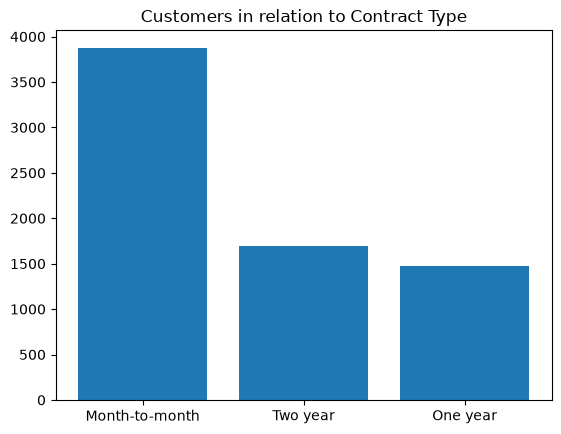

In [80]:
plt.bar(x=data['Contract'].value_counts().index, height=data['Contract'].value_counts())
plt.title(label='Customers in relation to Contract Type')
plt.show()

We notice that the month-to-month contract type dominates the dataset, about 55% of the contracts in it are monthly. While this subset is overrepresented, it suffices to say that it still has a considerable impact on churn, as we observed the ~0.427 probability of churn given a m2m contract. This does, however, affect the second tables findings, as the m2m contracts making up most of the churned base is due part in fact that it makes up most of the dataset.

Using: $$\text{H}_{o}\text{: contract and churn are independent,}\quad \text{H}_{a}\text{: contract and churn are dependent} $$

In [82]:
from scipy.stats import chi2_contingency

# Chi-test needs the contingency table, we do not normalize because it needs actual frequency counts
observed = pd.crosstab(data['Contract'],churn)
result=chi2_contingency(observed)
print('Successfully performed Chi-Squared Test.')


Successfully performed Chi-Squared Test.


In [95]:
# Print the results of the Chi-Squared Test
print(f"Test statistic: {result.statistic.round(3)}")
print(f"p-value: {result.pvalue}")
print(f"Degrees of freedom: {result.dof}")
print(f"Expected counts anticipated under Ho:\n{result.expected_freq.round(3)}")

Test statistic: 1184.597
p-value: 5.863038300673391e-258
Degrees of freedom: 2
Expected counts anticipated under Ho:
[[2846.692 1028.308]
 [1082.11   390.89 ]
 [1245.198  449.802]]


At the significance level of 5%, there is overwhelming evidence of an association between contract and churn. This concludes our exploration for Contract vs. Churn. We will move onto creating a more efficient method of exploring the other models efficiently, and measuring the predictive contributions through the building of a model.

---

Recalling some of the columns, we can make obvious connections between some. Particularly, we have:
- `PhoneService` and `MultipleLines`: Multiple lines is dependent on whether the customer even has a phone service. 
- `InternetService`,`OnlineSecurity`,`OnlineBackup`,`DeviceProtection`,`TechSupport`,`StreamingTV`,`StreamingMovies`: All the listed columns are dependent on whether the customer has internet service.

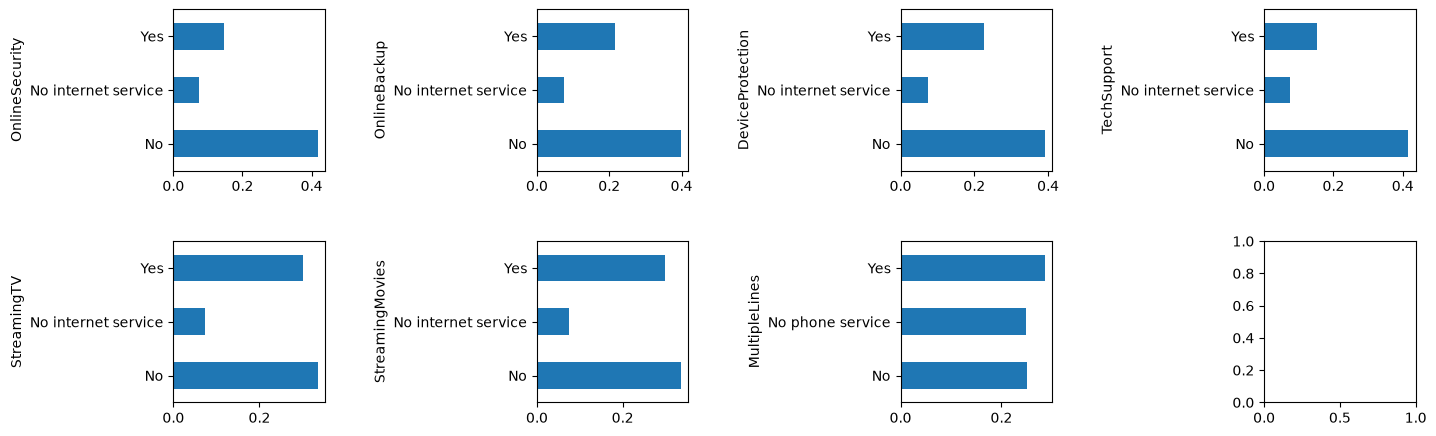

In [120]:
fig, axes = plt.subplots(2, 4, figsize=(15, 5))
children = ['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','MultipleLines']

# Make bar plots for each relative frequency table
for child,ax in zip(children,axes.flat):
    # Churn rates against their status (Yes, No, No internet service)
    rates=pd.crosstab(data[child],churn,normalize='index')
    rates['Yes'].plot(kind='barh', ax=ax)
    plt.tight_layout(pad=3)
plt.show()

Customers subscribed to Online Security and Tech Support exhibit substantially lower churn rates compared to customers with internet services who do subscribe. Streaming services show a weaker relationship with churn, both those who do subscribe and don't exhibit higher churn rates. Customers without internet services exhibit low churn as they represent the same underlying customer group. With phone service, we observe that customers subscribed to multiple lines actually exhibit a higher churn rate compared to those with a single line. "No" and "No phone service" represent the same customer group, hence their equal values.

---

## Preprocessing